In [4]:
# Binomial 

In [1]:
pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Dis. Bernoullis
prob of failure is  0.1
pron of success is  0.9
empirical pmf  [np.float64(0.9009), np.float64(0.0991)]
theoretical pmf  [0.9, 0.1]


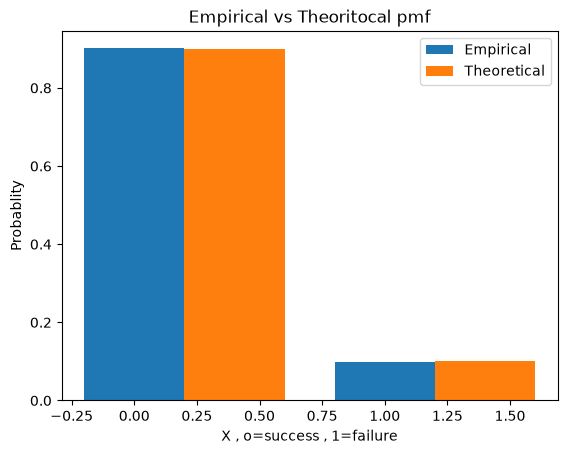

Empirical expactation is  0.0991
Theoretical expectation is  0.1
Empirical variance is  0.08927919
Theoretical variance is  0.09000000000000001
empirical 0.0991
theoretical 0.1


In [3]:
import numpy as np 
import matplotlib.pyplot as plt

# 1 this is Bernoullis Distribution
p = 0.10 # X = 0  , prob of failure 
q = 1-p  # X = 1  , prob of success 

print("Dis. Bernoullis")
print("prob of failure is ", p)
print("pron of success is ", q)

# 2 simulate 20,000 requests
n = 20000
np.random.seed(42)
X = np.random.binomial(1,p,n)

# empirical & theoretical pmf
empirical = [ np.mean(X==0), np.mean(X==1) ]

theoretical = [q , p]

print("empirical pmf ", empirical)
print("theoretical pmf ", theoretical)

# plot the pmf
x =[0 , 1]

plt.bar(x,empirical , width=0.4 , label="Empirical")
plt.bar( [i+0.4 for i in x ],theoretical ,width=0.4 , label="Theoretical")

plt.xlabel("X , o=success , 1=failure")
plt.ylabel("Probablity")
plt.title("Empirical vs Theoritocal pmf")
plt.legend()
plt.show()

# 4 Expectation and variance 
print("Empirical expactation is ", np.mean(X))
print("Theoretical expectation is ", p )

print("Empirical variance is ", np.var(X))
print("Theoretical variance is ", p*q )

# 5 prob of failure 
print("empirical", np.mean(X==1))
print("theoretical" , p)

In [6]:
# fraud detection system



import numpy as np
import pandas as pd

# Given values
n = 10000

# (a) Simulate transactions
np.random.seed(1)

fraud = np.random.rand(n) < 0.08
flag = []

for i in range(n):
    if fraud[i]:
        flag.append(np.random.rand() < 0.85)
    else:
        flag.append(np.random.rand() < 0.10)

flag = np.array(flag)

# (b) Create table
FF = sum(fraud & flag)
FN = sum(fraud & ~flag)
GF = sum(~fraud & flag)
GN = sum(~fraud & ~flag)

table = pd.DataFrame(
    [[FF, FN], [GF, GN]],
    index=["Fraudulent", "Genuine"],
    columns=["Flagged", "Not Flagged"]
)

print("Transaction Table:")
print(table)

# (c) Simulated probabilities
p1 = sum(flag) / n
p2 = FF / sum(flag)

print("\nSimulated Results:")
print("P(Flagged) =", p1)
print("P(Fraud | Flagged) =", p2)

# (d) Theoretical probabilities
p3 = (0.08 * 0.85) + (0.92 * 0.10)
p4 = (0.08 * 0.85) / p3

print("\nTheoretical Results:")
print("P(Flagged) =", p3)
print("P(Fraud | Flagged) =", p4)


Transaction Table:
            Flagged  Not Flagged
Fraudulent      676          122
Genuine         925         8277

Simulated Results:
P(Flagged) = 0.1601
P(Fraud | Flagged) = 0.42223610243597753

Theoretical Results:
P(Flagged) = 0.16000000000000003
P(Fraud | Flagged) = 0.42499999999999993


Distribution: Binomial
n = 12
p = 0.2
Possible values: 0 to 12

PMF Table:
     X  Empirical PMF  Theoretical PMF
0    0        0.06910     6.871948e-02
1    1        0.20615     2.061584e-01
2    2        0.27980     2.834678e-01
3    3        0.23910     2.362232e-01
4    4        0.13485     1.328756e-01
5    5        0.05235     5.315022e-02
6    6        0.01500     1.550215e-02
7    7        0.00325     3.321889e-03
8    8        0.00040     5.190451e-04
9    9        0.00000     5.767168e-05
10  10        0.00000     4.325376e-06
11  11        0.00000     1.966080e-07
12  12        0.00000     4.096000e-09


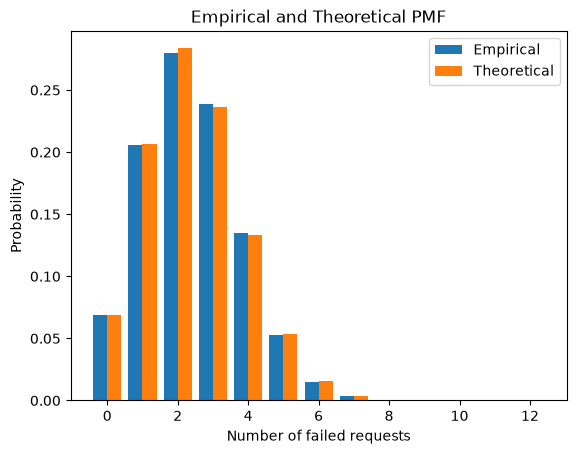


Expectation and Variance:
             Empirical  Theoretical
Expectation    2.40015         2.40
Variance       1.90773         1.92

Probability P(X >= 3):
Empirical = 0.44495
Theoretical = 0.44165425152000026


In [8]:
# Server monitoring 


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Given values
n = 12
p = 0.20
minutes = 20000

# (a) Binomial Distribution
print("Distribution: Binomial")
print("n =", n)
print("p =", p)
print("Possible values: 0 to 12")

# (b) Simulate 20000 minutes
np.random.seed(1)
X = np.random.binomial(n, p, minutes)

# Empirical PMF
x = np.arange(13)
empirical = np.bincount(X, minlength=13) / minutes

# (c) Theoretical PMF
from scipy.stats import binom

theoretical = binom.pmf(x, n, p)

# Display PMF table
print("\nPMF Table:")
print(pd.DataFrame({
    "X": x,
    "Empirical PMF": empirical,
    "Theoretical PMF": theoretical
}))

# Plot both PMFs
plt.bar(x - 0.2, empirical, width=0.4, label="Empirical")
plt.bar(x + 0.2, theoretical, width=0.4, label="Theoretical")

plt.xlabel("Number of failed requests")
plt.ylabel("Probability")
plt.title("Empirical and Theoretical PMF")
plt.legend()
plt.show()

# (d) Expectation and Variance
emp_mean = np.mean(X)
emp_var = np.var(X)

theo_mean = n * p
theo_var = n * p * (1 - p)

table = pd.DataFrame({
    "Empirical": [emp_mean, emp_var],
    "Theoretical": [theo_mean, theo_var]
}, index=["Expectation", "Variance"])

print("\nExpectation and Variance:")
print(table)

# (e) Example: Calculate P(X >= 3)
emp_prob = np.mean(X >= 3)
theo_prob = 1 - binom.cdf(2, n, p)

print("\nProbability P(X >= 3):")
print("Empirical =", emp_prob)
print("Theoretical =", theo_prob)



Threshold = 0.6
TN = 882, FP = 38, FN = 15, TP = 65
Sensitivity = 0.8125
Specificity = 0.9587
Precision   = 0.6311

Threshold = 0.35
TN = 618, FP = 302, FN = 3, TP = 77
Sensitivity = 0.9625
Specificity = 0.6717
Precision   = 0.2032

ROC AUC = 0.9586
Average precision = 0.7964
Anomaly prevalence = 0.0800


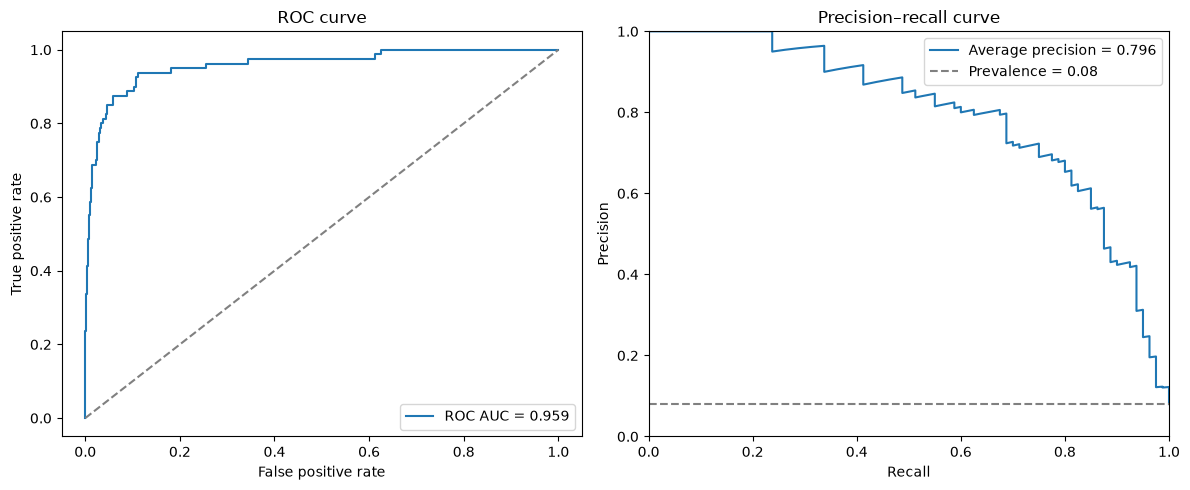

In [9]:
# roc 

import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    roc_curve,
    precision_recall_curve,
    roc_auc_score,
    average_precision_score
)

# Do not modify this data-generation code
rng = np.random.default_rng(42)

positive_scores = rng.beta(5, 2, size=80)
negative_scores = rng.beta(2, 5, size=920)

y_true = np.r_[np.ones(80, dtype=int), np.zeros(920, dtype=int)]
scores = np.r_[positive_scores, negative_scores]


def evaluate_threshold(threshold):

    # A. Convert scores into predicted classes
    y_pred = (scores >= threshold).astype(int)

    # B. Obtain TN, FP, FN and TP
    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    # C. Calculate sensitivity
    sensitivity = tp / (tp + fn)

    # D. Calculate specificity
    specificity = tn / (tn + fp)

    # E. Calculate precision
    precision = tp / (tp + fp)

    print(f"\nThreshold = {threshold}")
    print(f"TN = {tn}, FP = {fp}, FN = {fn}, TP = {tp}")
    print(f"Sensitivity = {sensitivity:.4f}")
    print(f"Specificity = {specificity:.4f}")
    print(f"Precision   = {precision:.4f}")


# Evaluate both thresholds
evaluate_threshold(0.60)
evaluate_threshold(0.35)


# F. Values needed for the ROC curve
fpr, tpr, _ = roc_curve(y_true, scores)

# G. Values needed for the precision–recall curve
pr_precision, pr_recall, _ = precision_recall_curve(y_true, scores)

# H. Calculate the two summary measures and class prevalence
roc_auc = roc_auc_score(y_true, scores)
avg_precision = average_precision_score(y_true, scores)
prevalence = np.mean(y_true)


print(f"\nROC AUC = {roc_auc:.4f}")
print(f"Average precision = {avg_precision:.4f}")
print(f"Anomaly prevalence = {prevalence:.4f}")


# Plot the curves
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(fpr, tpr, label=f"ROC AUC = {roc_auc:.3f}")
axes[0].plot([0, 1], [0, 1], "--", color="gray")

axes[0].set(
    title="ROC curve",
    xlabel="False positive rate",
    ylabel="True positive rate"
)

axes[0].legend()

axes[1].plot(
    pr_recall,
    pr_precision,
    label=f"Average precision = {avg_precision:.3f}"
)

axes[1].axhline(
    prevalence,
    linestyle="--",
    color="gray",
    label=f"Prevalence = {prevalence:.2f}"
)

axes[1].set(
    title="Precision–recall curve",
    xlabel="Recall",
    ylabel="Precision",
    xlim=(0, 1),
    ylim=(0, 1)
)

axes[1].legend()

plt.tight_layout()
plt.show()